# A4 / E3 — Fitur gaya — Anggota A

**Versi:** V3.1_A2_PROVISIONAL. **Split:** LATIH untuk fit, VALIDASI untuk evaluasi, UJI tetap terkunci.

Notebook ini mandiri (skrip tertanam) agar hasil dapat direproduksi. Jika anggota B memakai versi V3.1 berbeda, ubah `DATASET_PATH` dan catat versinya sebelum mengulang eksperimen.

In [1]:
%pip -q install numpy pandas scikit-learn

## 1. Hubungkan Google Drive
Simpan `DATASET_V3_1_KANDIDAT_OPERASIONAL.csv` di Drive. Mount Drive, lalu masukkan path CSV yang sebenarnya. Jika memilih upload lokal 175 MB, proses transfer dapat lebih lama.

In [2]:
from pathlib import Path
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Bukan Google Colab: gunakan lokasi CSV di perangkat ini.')

Mounted at /content/drive


In [5]:
DATASET_PATH = "/content/drive/MyDrive/Tugas/S2/Semester 1/PSP/Kelompok 5 - PSP/DATASET_V3_1_KANDIDAT_OPERASIONAL.csv"
assert Path(DATASET_PATH).is_file(), f"CSV tidak ditemukan. Ubah DATASET_PATH: {DATASET_PATH}"
print("Dataset ditemukan:", DATASET_PATH)

Dataset ditemukan: /content/drive/MyDrive/Tugas/S2/Semester 1/PSP/Kelompok 5 - PSP/DATASET_V3_1_KANDIDAT_OPERASIONAL.csv


## 2. Siapkan skrip eksperimen
Skrip sama dengan file Python yang disertakan dalam paket penyerahan.

In [6]:
%%writefile a4_e3_style.py
"""A4 / E3: style-only diagnostic, train/validation only.

Run: python scripts/a4_e3_style.py --dataset /path/to/DATASET_V3_1_KANDIDAT_OPERASIONAL.csv

No final TEST is read for training, tuning, or evaluation. Feature definitions are
fixed in code. This experiment DOES NOT demonstrate causal shortcut usage alone.
"""
import argparse
import hashlib
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

FEATURES = ["uppercase_ratio", "exclamation_count", "question_count", "allcaps_word_count", "word_count"]
LETTER_WORD = re.compile(r"\b[^\W\d_]+\b", flags=re.UNICODE)
SEED = 42


def style_features(text):
    text = "" if pd.isna(text) else str(text)
    n_letters = sum(ch.isalpha() for ch in text)
    upper = sum(ch.isupper() for ch in text)
    words_alpha = LETTER_WORD.findall(text)
    return (
        upper / n_letters if n_letters else 0.0,
        text.count("!"),
        text.count("?"),
        sum(len(word) > 2 and word.isupper() for word in words_alpha),
        len(text.split()),
    )


def metrics(y_true, y_pred):
    prec, rec, fs, support = precision_recall_fscore_support(
        y_true, y_pred, labels=[0, 1], zero_division=0
    )
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1]).tolist()
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "valid_precision": prec[0], "valid_recall": rec[0], "valid_f1": fs[0],
        "hoaks_precision": prec[1], "hoaks_recall": rec[1], "hoaks_f1": fs[1],
        "n_validasi": int(len(y_true)), "support_valid": int(support[0]),
        "support_hoaks": int(support[1]), "confusion_matrix_0_1": cm,
    }


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--dataset", required=True)
    p.add_argument("--clean-col", default="text_clean_v31")
    p.add_argument("--version", default="V3.1_A2_PROVISIONAL")
    p.add_argument("--outdir", default="results/anggota_a")
    p.add_argument("--class-weight", choices=["none", "balanced"], default="none")
    args = p.parse_args()
    out = Path(args.outdir)
    out.mkdir(parents=True, exist_ok=True)
    needed = ["raw_id", "source", "label", "random_split", "text_raw", args.clean_col]
    df = pd.read_csv(args.dataset, usecols=needed, low_memory=False)
    if df.raw_id.duplicated().any():
        raise ValueError("Duplikat raw_id")
    if not set(df.random_split.unique()) <= {"LATIH", "VALIDASI", "UJI"}:
        raise ValueError("Split tidak dikenali")
    subset = df.loc[df.random_split.isin(["LATIH", "VALIDASI"])].copy()
    assert len(subset) == 26270 and (subset.random_split == "VALIDASI").sum() == 2919
    train = subset.random_split.eq("LATIH").to_numpy()
    val = subset.random_split.eq("VALIDASI").to_numpy()
    rows = []
    all_pred = []
    feature_desc = []
    for condition, col in [("raw", "text_raw"), ("clean_v31", args.clean_col)]:
        feats = np.asarray([style_features(x) for x in subset[col].fillna("")], dtype=np.float64)
        pipe = Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(max_iter=3000, random_state=SEED,
                                       class_weight=None if args.class_weight == "none" else "balanced")),
        ])
        pipe.fit(feats[train], subset.loc[train, "label"].to_numpy())
        pred = pipe.predict(feats[val])
        y_val = subset.loc[val, "label"].to_numpy()
        scores = metrics(y_val, pred)
        rows.append({"experiment": "E3", "data_version": args.version,
                     "split": "VALIDASI", "model": "LogisticRegression", "condition": condition,
                     "seed": SEED, "class_weight": args.class_weight, **scores})
        d = subset.loc[val, ["raw_id", "source", "label"]].copy()
        d["condition"] = condition
        d["predicted_label"] = pred
        all_pred.append(d)
        means = pd.DataFrame(feats, columns=FEATURES)
        means["label"] = subset.label.to_numpy()
        means["split"] = subset.random_split.to_numpy()
        means = means.loc[means.split == "LATIH"].groupby("label")[FEATURES].mean()
        for lbl, row in means.iterrows():
            feature_desc.append({"condition": condition, "label": int(lbl), **row.to_dict()})
        print(f"{condition:10s} | macro-F1 VALIDASI = {scores['macro_f1']:.4f} | accuracy = {scores['accuracy']:.4f}")
    pd.DataFrame(rows).to_csv(out / "E3_METRIK_VALIDASI.csv", index=False)
    pd.concat(all_pred, ignore_index=True).to_csv(out / "E3_PREDIKSI_VALIDASI.csv", index=False)
    pd.DataFrame(feature_desc).to_csv(out / "E3_RERATA_FITUR_LATIH.csv", index=False)
    (out / "E3_METADATA.json").write_text(json.dumps({
        "data_version": args.version, "dataset_file": Path(args.dataset).name,
        "dataset_sha256": hashlib.sha256(Path(args.dataset).read_bytes()).hexdigest(),
        "features": FEATURES, "seed": SEED, "train_count": int(train.sum()),
        "validation_count": int(val.sum()), "test_accessed_for_experiment": False,
        "logistic_regression": {"max_iter": 3000, "class_weight": args.class_weight,
                                "scaler_fit": "TRAIN_ONLY", "C": 1.0},
        "sklearn_version": sklearn.__version__,
        "caveat": "Source and label confounded; raw includes dataset artifacts. Do not interpret as causal attribution.",
    }, indent=2, ensure_ascii=False), encoding="utf-8")


if __name__ == "__main__":
    main()


Writing a4_e3_style.py


In [7]:
%%writefile a4_e3_ablation.py
"""Optional E3 diagnosis: compare all 5 vs 4 excluding word count vs length only."""
import argparse
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from a4_e3_style import style_features


def main():
    p = argparse.ArgumentParser()
    p.add_argument('--dataset', required=True)
    p.add_argument('--clean-col', default='text_clean_v31')
    p.add_argument('--outdir', default='results/anggota_a')
    args = p.parse_args()
    d = pd.read_csv(args.dataset, usecols=['raw_id','label','random_split',args.clean_col])
    d = d.loc[d.random_split.isin(['LATIH','VALIDASI'])]
    X = np.asarray([style_features(t) for t in d[args.clean_col].fillna('')], dtype=float)
    y = d.label.to_numpy()
    mtrain = d.random_split.eq('LATIH').to_numpy()
    mval = d.random_split.eq('VALIDASI').to_numpy()
    configs = {'all_5': slice(0,5), 'style_without_word_count': slice(0,4), 'word_count_only': slice(4,5)}
    rows = []
    for name, indices in configs.items():
        clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=42))
        clf.fit(X[mtrain, indices], y[mtrain])
        pred = clf.predict(X[mval, indices])
        row = {'experiment':'E3_ABLATION', 'condition':name, 'split':'VALIDASI',
               'data_version':'V3.1_A2_PROVISIONAL', 'n_train':int(mtrain.sum()),
               'n_validasi':int(mval.sum()),'seed':42,
               'macro_f1':f1_score(y[mval], pred, average='macro'),
               'accuracy':accuracy_score(y[mval], pred)}
        rows.append(row)
        print(name, 'macro-F1', f'{row["macro_f1"]:.4f}', flush=True)
    out = Path(args.outdir);out.mkdir(parents=True,exist_ok=True)
    pd.DataFrame(rows).to_csv(out / 'E3_ABLATION_METRIK_VALIDASI.csv',index=False)
if __name__ == '__main__':main()


Writing a4_e3_ablation.py


In [9]:
import subprocess, sys
subprocess.run([sys.executable, "a4_e3_style.py", "--dataset", DATASET_PATH, "--outdir", "HASIL_E3"], check=True)
subprocess.run([sys.executable, "a4_e3_ablation.py", "--dataset", DATASET_PATH, "--outdir", "HASIL_E3"], check=True)

CompletedProcess(args=['/usr/bin/python3', 'a4_e3_ablation.py', '--dataset', '/content/drive/MyDrive/Tugas/S2/Semester 1/PSP/Kelompok 5 - PSP/DATASET_V3_1_KANDIDAT_OPERASIONAL.csv', '--outdir', 'HASIL_E3'], returncode=0)

## 3. Periksa hasil VALIDASI dan unduh ZIP
Jangan melaporkan angka sebagai UJI. Untuk finalisasi, gunakan versi data dan konfigurasi yang disepakati bersama anggota B.

In [10]:
import pandas as pd
from IPython.display import display
display(pd.read_csv("HASIL_E3/E3_METRIK_VALIDASI.csv"))

,experiment,data_version,split,model,condition,seed,class_weight,accuracy,macro_f1,valid_precision,valid_recall,valid_f1,hoaks_precision,hoaks_recall,hoaks_f1,n_validasi,support_valid,support_hoaks,confusion_matrix_0_1
0,E3,V3.1_A2_PROVISIONAL,VALIDASI,LogisticRegression,raw,42,none,0.963686,0.954440,0.961341,0.988979,0.974965,0.970207,0.900240,0.933915,2919,2087,832,"[[2064, 23], [83, 749]]"
1,E3,V3.1_A2_PROVISIONAL,VALIDASI,LogisticRegression,clean_v31,42,none,0.964714,0.955815,0.963119,0.988500,0.975644,0.969112,0.905048,0.935985,2919,2087,832,"[[2063, 24], [79, 753]]"


In [11]:
import shutil
from pathlib import Path
out = shutil.make_archive("HASIL_E3_VALIDASI", "zip", "HASIL_E3")
print("File ZIP:", out)
try:
    from google.colab import files
    files.download(out)
except ImportError:
    pass

File ZIP: /content/HASIL_E3_VALIDASI.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Visualisasi

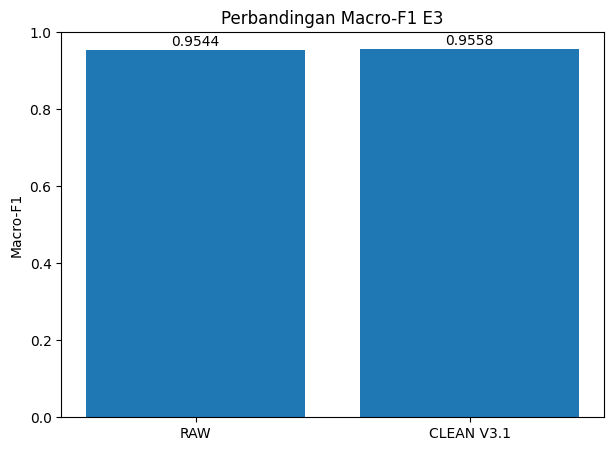

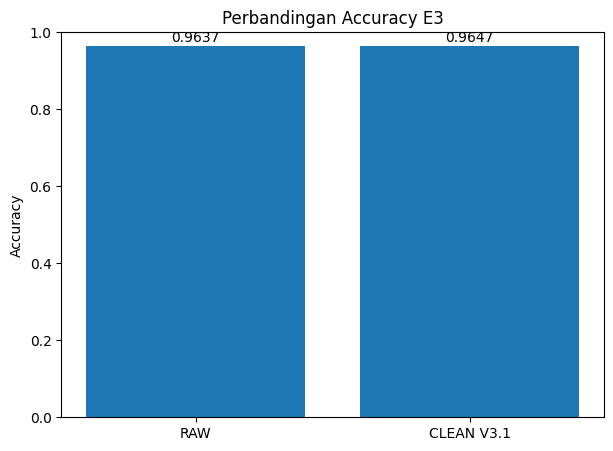

In [13]:
import matplotlib.pyplot as plt

macro_f1_raw = 0.954440
macro_f1_clean = 0.955815
acc_raw = 0.963686
acc_clean = 0.964714

labels = ["RAW", "CLEAN V3.1"]
macro_f1_values = [macro_f1_raw, macro_f1_clean]
acc_values = [acc_raw, acc_clean]

# Chart Macro-F1
plt.figure(figsize=(7,5))
plt.bar(labels, macro_f1_values)
plt.title("Perbandingan Macro-F1 E3")
plt.ylabel("Macro-F1")
plt.ylim(0, 1.0)
for i, v in enumerate(macro_f1_values):
    plt.text(i, v + 0.01, f"{v:.4f}", ha='center')
plt.show()

# Chart Accuracy
plt.figure(figsize=(7,5))
plt.bar(labels, acc_values)
plt.title("Perbandingan Accuracy E3")
plt.ylabel("Accuracy")
plt.ylim(0, 1.0)
for i, v in enumerate(acc_values):
    plt.text(i, v + 0.01, f"{v:.4f}", ha='center')
plt.show()

In [16]:
plt.savefig(
    "E3_MACRO_F1_COMPARISON.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>